In [16]:
import time
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import pro_ang1, legendre, chebyt
from sklearn.linear_model import LinearRegression


In [17]:
def Orders(s):
    """Return (i, j) with (i + 1)(j + 1) <= s + 1."""
    return [
        (i, j)
        for i in range(s + 1)
        for j in range((s + 1) // (i + 1))
    ]

In [18]:
# Vary the hyperbolic-cross order parameter n
Para_slep = list(range(2, 26))
#Para_slep = np.linspace(5, 25, 10).astype(int)

# Fixed number of training samples
Nsamples = np.array([1000])

# Slepian bandwidth
w = 8

# Fixed test-set size
Ntest = 1000

total_runs = 1

In [19]:
# Generate random sample points uniformly on [-1, 1]^2
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    """Generate independent uniform samples on [-1, 1]^2."""
    return rng.uniform(-1, 1, size=(int(n_samples), 2))

In [20]:
# Target function to approximate
def funct(z):
    """
    Evaluate g_3(x, y) = exp(-pi * (x^2 + y^2 + 0.2*x*y)).

    Parameters
    ----------
    z : ndarray, shape (n_samples, 2)
        Sample coordinates (x, y).

    Returns
    -------
    ndarray, shape (n_samples,)
        Target function values.
    """
    x, y = z[:, 0], z[:, 1]
    return np.exp(-np.pi * (x**2 + y**2 + 0.2*x*y))


In [21]:
def Cheby(X, Y, j, k):
    norm_x = np.sqrt(np.pi) if j == 0 else np.sqrt(np.pi / 2)
    norm_y = np.sqrt(np.pi) if k == 0 else np.sqrt(np.pi / 2)

    Tx = chebyt(j)(X) / norm_x
    Ty = chebyt(k)(Y) / norm_y

    return Tx * Ty

In [22]:
def MatrixC(samp, k):
    """Construct the 2D Chebyshev design matrix for hyperbolic-cross order k."""
    Ords = Orders(k)
    A = np.zeros((len(samp), len(Ords)))

    for m, (x, y) in enumerate(samp):
        for i, (j, ell) in enumerate(Ords):
            A[m, i] = Cheby(x, y, j, ell)

    return A

In [23]:
def Legend(X, Y, j, k):
    """Evaluate the normalized 2D tensor-product Legendre basis."""
    norm_x = np.sqrt(2 / (2 * j + 1))
    norm_y = np.sqrt(2 / (2 * k + 1))

    Px = legendre(j)(X) / norm_x
    Py = legendre(k)(Y) / norm_y

    return Px * Py


In [24]:
def MatrixL(samp, k):
    """Construct the 2D Legendre design matrix for hyperbolic-cross order k."""
    Ords = Orders(k)
    A = np.zeros((len(samp), len(Ords)))

    for m, (x, y) in enumerate(samp):
        for i, (j, ell) in enumerate(Ords):
            A[m, i] = Legend(x, y, j, ell)

    return A

In [25]:
def NorSlep(j, c):
    """Approximate the L2([-1, 1]) norm of the angular Slepian function."""
    theta = np.linspace(-1, 1, 1001)
    values = pro_ang1(0, j, c, theta)[0]

    # Exclude endpoints, where pro_ang1 returns NaN
    values = values[1:-1]
    theta = theta[1:-1]

    return np.sqrt(np.trapezoid(np.abs(values)**2, theta))


norms_ = np.array([NorSlep(j, w) for j in range(max(Para_slep))])

In [26]:
def PSWF(x, j, c):
    """Evaluate the normalized 1D prolate spheroidal angular function."""
    b = 0
    psaf_values = pro_ang1(b, j, c, x)[0]
    return psaf_values / norms_[j]


In [27]:
def product_of_pswf(x1, x2, i, j, c):
    """Evaluate the 2D tensor-product Slepian basis function."""
    return PSWF(x1, i, c) * PSWF(x2, j, c)

In [28]:
def Matrix(samp, k):
    """Construct the 2D Slepian design matrix for hyperbolic-cross order k."""
    Ords = Orders(k)
    A = np.zeros((len(samp), len(Ords)))

    for m, (x, y) in enumerate(samp):
        for i, (j, ell) in enumerate(Ords):
            A[m, i] = product_of_pswf(x, y, j, ell, w)

    return A

In [29]:
# Allocate error arrays
MSE_cheby = np.zeros((len(Para_slep), len(Nsamples), total_runs))
MSE_leg   = np.zeros_like(MSE_cheby)
MSE_slep  = np.zeros_like(MSE_cheby)

start_time = time.time()
total_iterations = total_runs * len(Para_slep) * len(Nsamples)
counter = 0

for run in range(total_runs):

    # Generate the largest training set once
    SamSet_ = generate_samples(Nsamples[-1])
    y_ = funct(SamSet_)

    # Independent test set of fixed size
    TestSet = generate_samples(Ntest)
    Values_test = funct(TestSet)

    for orde, n in enumerate(Para_slep):

        # n is the manuscript's HC order;
        # Orders(n-1) implements Lambda_HC_{n-1}
        s = n - 1

        # Construct design matrices for this order
        A_c_ = MatrixC(SamSet_, s)
        A_l_ = MatrixL(SamSet_, s)
        A_s_ = Matrix(SamSet_, s)

        test_cheby = MatrixC(TestSet, s)
        test_leg   = MatrixL(TestSet, s)
        test_slep  = Matrix(TestSet, s)

        for k, m in enumerate(Nsamples):

            # Use the first m training samples
            A_c = A_c_[:m, :]
            A_l = A_l_[:m, :]
            A_s = A_s_[:m, :]
            y = y_[:m]

            # Chebyshev least squares
            coef_c = np.linalg.lstsq(A_c, y, rcond=None)[0]
            pred_c = test_cheby @ coef_c
            MSE_cheby[orde, k, run] = (
                np.linalg.norm(pred_c - Values_test) / np.sqrt(Ntest)
            )

            # Legendre least squares
            coef_l = np.linalg.lstsq(A_l, y, rcond=None)[0]
            pred_l = test_leg @ coef_l
            MSE_leg[orde, k, run] = (
                np.linalg.norm(pred_l - Values_test) / np.sqrt(Ntest)
            )

            # Slepian least squares
            coef_s = np.linalg.lstsq(A_s, y, rcond=None)[0]
            pred_s = test_slep @ coef_s
            MSE_slep[orde, k, run] = (
                np.linalg.norm(pred_s - Values_test) / np.sqrt(Ntest)
            )

            counter += 1
            elapsed = time.time() - start_time
            remaining = elapsed * (total_iterations - counter) / counter

            print(
                f"Run {run + 1}/{total_runs}, n={n}, m={m}: "
                f"RMSE (Cheby, Legendre, Slepian) = "
                f"({MSE_cheby[orde,k,run]:.4e}, "
                f"{MSE_leg[orde,k,run]:.4e}, "
                f"{MSE_slep[orde,k,run]:.4e}); "
                f"{100 * counter / total_iterations:.1f}% complete; "
                f"~{remaining:.1f}s remaining"
            )

Run 1/1, n=2, m=1000: RMSE (Cheby, Legendre, Slepian) = (2.6200e-01, 2.6200e-01, 4.7230e-02); 4.2% complete; ~25.4s remaining
Run 1/1, n=3, m=1000: RMSE (Cheby, Legendre, Slepian) = (1.4018e-01, 1.4018e-01, 2.2968e-02); 8.3% complete; ~33.0s remaining
Run 1/1, n=4, m=1000: RMSE (Cheby, Legendre, Slepian) = (1.3960e-01, 1.3960e-01, 1.4988e-02); 12.5% complete; ~43.1s remaining
Run 1/1, n=5, m=1000: RMSE (Cheby, Legendre, Slepian) = (1.1380e-01, 1.1380e-01, 5.3402e-03); 16.7% complete; ~50.8s remaining
Run 1/1, n=6, m=1000: RMSE (Cheby, Legendre, Slepian) = (1.1417e-01, 1.1417e-01, 5.3403e-03); 20.8% complete; ~61.6s remaining
Run 1/1, n=7, m=1000: RMSE (Cheby, Legendre, Slepian) = (1.1290e-01, 1.1290e-01, 5.2665e-03); 25.0% complete; ~68.6s remaining
Run 1/1, n=8, m=1000: RMSE (Cheby, Legendre, Slepian) = (1.1406e-01, 1.1406e-01, 4.0080e-03); 29.2% complete; ~76.1s remaining
Run 1/1, n=9, m=1000: RMSE (Cheby, Legendre, Slepian) = (5.5191e-02, 5.5191e-02, 1.9376e-03); 33.3% complete; ~82

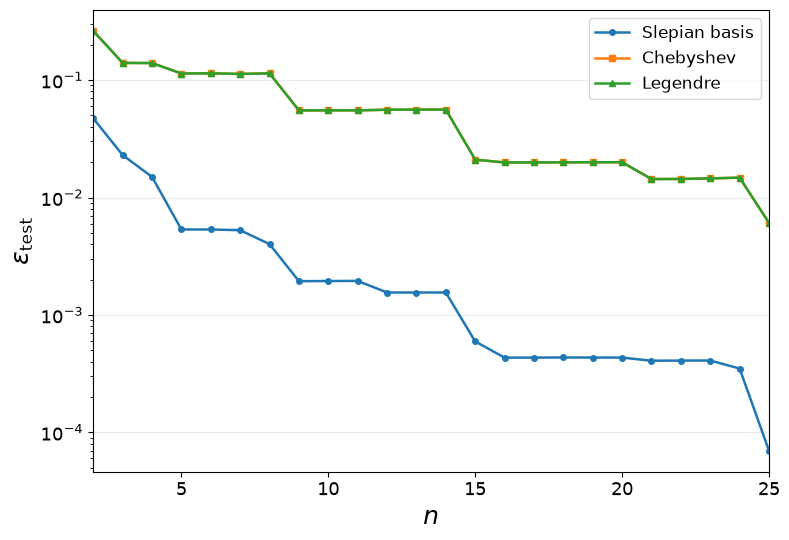

In [30]:

# Plot error versus hyperbolic-cross order n
plt.figure(figsize=(8, 5.5))

results_mean_cheby = np.mean(MSE_cheby, axis=2)
results_mean_leg = np.mean(MSE_leg, axis=2)
results_mean_slep = np.mean(MSE_slep, axis=2)

plt.semilogy(Para_slep, results_mean_slep[:, 0],
             '-o', markersize=4, linewidth=1.8, label="Slepian basis")
plt.semilogy(Para_slep, results_mean_cheby[:, 0],
             '-s', markersize=4, linewidth=1.8, label="Chebyshev")
plt.semilogy(Para_slep, results_mean_leg[:, 0],
             '-^', markersize=4, linewidth=1.8, label="Legendre")

plt.xlabel(r'$n$', fontsize=18)
plt.ylabel(r'$\epsilon_{\mathrm{test}}$', fontsize=18)

plt.xlim(2, 25)
plt.xticks([5, 10, 15, 20, 25], fontsize=13)
plt.yticks(fontsize=13)

plt.legend(fontsize=12, loc='best', frameon=True)
plt.grid(True, axis='y', which='major', alpha=0.25)

plt.tight_layout()
plt.savefig("errorvsparams2D_right.pdf", bbox_inches="tight", dpi=300)
plt.show()



In [22]:
print("Nsamples:", Nsamples)
print("Para_slep:", Para_slep)
print("MSE shapes:", MSE_cheby.shape, MSE_leg.shape, MSE_slep.shape)
print("Figure files saved:", __import__("os").path.exists("errorvsparams2D_withNoy2.pdf"))
print("Slepian errors:", MSE_slep[:, 0, 0])
print("Chebyshev errors:", MSE_cheby[:, 0, 0])
print("Legendre errors:", MSE_leg[:, 0, 0])

Nsamples: [1000]
Para_slep: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
MSE shapes: (24, 1, 1) (24, 1, 1) (24, 1, 1)
Figure files saved: True
Slepian errors: [4.72295833e-02 2.29675098e-02 1.49880836e-02 5.34017169e-03
 5.34033406e-03 5.26651722e-03 4.00802060e-03 1.93764004e-03
 1.94364307e-03 1.94775276e-03 1.55183851e-03 1.55138373e-03
 1.55213077e-03 5.94054009e-04 4.32595188e-04 4.32939100e-04
 4.33980795e-04 4.33392105e-04 4.33012606e-04 4.07151087e-04
 4.08309734e-04 4.08935545e-04 3.49350260e-04 6.97632430e-05]
Chebyshev errors: [0.26199596 0.14018045 0.13960115 0.11380487 0.11417339 0.11289608
 0.11406203 0.0551913  0.05525392 0.05523489 0.05595141 0.05605492
 0.05609265 0.02101132 0.01988369 0.01987632 0.0199346  0.01996096
 0.01998365 0.01435706 0.01438605 0.01454595 0.01475896 0.00607497]
Legendre errors: [0.26199596 0.14018045 0.13960115 0.11380487 0.11417339 0.11289608
 0.11406203 0.0551913  0.05525392 0.05523489 0.05595141 0.0

In [147]:
import os

# Número total de núcleos disponibles para Python
total_cores = os.cpu_count()
print("Núcleos totales:", total_cores)

Núcleos totales: 32
